# Contrôle de contamination PlantVillage ↔ PlantDoc (PFA 07)

**Objectif :** vérifier qu'aucune image du **test externe** (PlantDoc, cinq classes retenues) n'est, en réalité, une copie d'une image de PlantVillage (corpus d'entraînement). Une telle copie fausserait la mesure de généralisation.

**Méthode**
1. **Copies exactes** : comparaison des empreintes SHA-256 des deux manifestes.
2. **Copies redimensionnées ou recompressées** : comparaison des empreintes perceptuelles (dHash 64 bits) de chaque image PlantDoc contre **toutes** les images de PlantVillage, avec les **8 orientations** de l'image (retournements et rotations).
3. **Contrôle visuel** des meilleurs candidats (paires côte à côte), puis décision enregistrée dans un fichier.

**Prérequis :** `manifest.csv` des deux audits, les deux corpus clonés et, facultatif, `partition.csv` pour savoir si une image PlantVillage appariée est en entraînement, validation ou test.

**Limites :** l'empreinte perceptuelle détecte les copies redimensionnées ou recompressées, mais pas les recadrages importants, les changements de couleur ni les incrustations. Une absence de candidat réduit le risque sans l'éliminer.

## 0. Configuration

In [1]:
from pathlib import Path

PV_MANIFEST = Path("audit/pv/manifest.csv")
PD_MANIFEST = Path("audit/pd/manifest.csv")
PV_ROOT = Path("PlantVillage-Dataset/raw/color")      # dossier ROOT utilisé pour l'audit PlantVillage
PD_ROOT = Path("PlantDoc-Dataset")                    # dossier ROOT utilisé pour l'audit PlantDoc
PARTITION = Path("partitions/pv/partition.csv")       # facultatif (ignoré s'il n'existe pas)
OUT = Path("contamination")

THRESHOLD = 7        # distance de Hamming max pour un candidat (<= 7)
SURE = 3             # distance <= SURE : doublon probable
N_PAIRS = 12         # nombre de paires affichées pour contrôle visuel

## 1. Chargement

In [2]:
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

assert THRESHOLD <= 7, "THRESHOLD doit être <= 7"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50, "display.width", 200)

pv = pd.read_csv(PV_MANIFEST)
pdm = pd.read_csv(PD_MANIFEST)

pv = pv[pv["readable"].astype(bool)].copy()
pd_ext = pdm[pdm["readable"].astype(bool) & pdm["keep"].astype(bool) & (pdm["class_retained"] != "hors_perimetre")].copy()
print(f"PlantVillage : {len(pv)} images lisibles (toutes classes tomate).")
print(f"PlantDoc : {len(pd_ext)} images du test externe (cinq classes retenues, après exclusions).")
display(pd_ext.groupby("class_retained").size().rename("n_images").reset_index())
print("Tableau 1 - Images PlantDoc du test externe, par classe retenue.")

PlantVillage : 18160 images lisibles (toutes classes tomate).
PlantDoc : 502 images du test externe (cinq classes retenues, après exclusions).


,class_retained,n_images
0,alternariose_precoce,88
1,cladosporiose,91
2,mildiou_tardif,111
3,saine,63
4,septoriose,149


Tableau 1 - Images PlantDoc du test externe, par classe retenue.


## 2. Copies exactes (SHA-256)

In [3]:
common = set(pv["sha256"]) & set(pd_ext["sha256"])
print(f"Fichiers strictement identiques entre PlantVillage et le test externe PlantDoc : {len(common)}")
if common:
    display(pd_ext[pd_ext["sha256"].isin(common)][["image_id", "class_retained", "sha256"]])

Fichiers strictement identiques entre PlantVillage et le test externe PlantDoc : 0


## 3. Copies redimensionnées ou recompressées (dHash, 8 orientations)

Pour chaque image PlantDoc, on calcule le dHash de ses 8 orientations (original, retournements, rotations) et on cherche, parmi toutes les images PlantVillage, la plus proche en distance de Hamming (0 = identique, environ 32 = sans rapport).

In [4]:
RESAMPLE = Image.Resampling.LANCZOS
TR = Image.Transpose
VARIANTS = [("original", None), ("flip_h", TR.FLIP_LEFT_RIGHT), ("flip_v", TR.FLIP_TOP_BOTTOM),
            ("rot90", TR.ROTATE_90), ("rot180", TR.ROTATE_180), ("rot270", TR.ROTATE_270),
            ("transpose", TR.TRANSPOSE), ("transverse", TR.TRANSVERSE)]
LUT = np.array([bin(i).count("1") for i in range(1 << 16)], dtype=np.uint8)


def dhash(im) -> int:
    s = np.asarray(im.convert("L").resize((9, 8), RESAMPLE), dtype=np.int16)
    bits = (s[:, 1:] > s[:, :-1]).ravel()
    return int("".join("1" if b else "0" for b in bits), 2)


def hamming_matrix(a, b):
    x = a[:, None] ^ b[None, :]
    m = np.uint64(0xFFFF)
    return LUT[x & m] + LUT[(x >> np.uint64(16)) & m] + LUT[(x >> np.uint64(32)) & m] + LUT[(x >> np.uint64(48)) & m]


pv_hash = np.array([int(h, 16) for h in pv["dhash"]], dtype=np.uint64)
pv_ids = pv["image_id"].to_numpy()
pv_rel = pv["relpath"].to_numpy()
pv_cls = pv["class_retained"].to_numpy()

rows = []
for r in pd_ext.itertuples():
    with Image.open(PD_ROOT / r.relpath) as im:
        im.load()
        hs = np.array([dhash(im if t is None else im.transpose(t)) for _, t in VARIANTS], dtype=np.uint64)
    d = hamming_matrix(hs, pv_hash)
    v, j = np.unravel_index(d.argmin(), d.shape)
    rows.append({"pd_image_id": r.image_id, "pd_relpath": r.relpath, "pd_class": r.class_retained,
                 "pv_image_id": pv_ids[j], "pv_relpath": pv_rel[j], "pv_class": pv_cls[j],
                 "distance": int(d.min()), "variante": VARIANTS[v][0]})

best = pd.DataFrame(rows).sort_values(["distance", "pd_image_id"]).reset_index(drop=True)
best["meme_classe"] = best["pd_class"] == best["pv_class"]

if PARTITION.exists():
    part = pd.read_csv(PARTITION)[["image_id", "partition"]].rename(columns={"image_id": "pv_image_id", "partition": "pv_partition"})
    best = best.merge(part, on="pv_image_id", how="left")
    best["pv_partition"] = best["pv_partition"].fillna("hors_partition")

display(best.head(15))
print("Tableau 2 - Les 15 images PlantDoc dont une image PlantVillage est la plus proche (distance de Hamming minimale sur 8 orientations).")

,pd_image_id,pd_relpath,pd_class,pv_image_id,pv_relpath,pv_class,distance,variante,meme_classe,pv_partition
0,plantdoc:test/Tomato Septoria leaf spot/2STEM.jpg,test/Tomato Septoria leaf spot/2STEM.jpg,septoriose,plantvillage:Tomato___Bacterial_spot/6d746b6c-...,Tomato___Bacterial_spot/6d746b6c-52f8-4831-b54...,hors_perimetre,6,rot180,False,hors_partition
1,plantdoc:train/Tomato leaf/L.peruv-assort.jpg,train/Tomato leaf/L.peruv-assort.jpg,saine,plantvillage:Tomato___Bacterial_spot/cce9e2aa-...,Tomato___Bacterial_spot/cce9e2aa-2027-474d-9c5...,hors_perimetre,6,rot90,False,hors_partition
2,plantdoc:train/Tomato mold leaf/119B_Tom_Mold.jpg,train/Tomato mold leaf/119B_Tom_Mold.jpg,cladosporiose,plantvillage:Tomato___Septoria_leaf_spot/43a56...,Tomato___Septoria_leaf_spot/43a563e9-03a7-48d7...,septoriose,6,original,False,hors_partition
3,plantdoc:train/Tomato mold leaf/Leaf+Mold+uppe...,train/Tomato mold leaf/Leaf+Mold+upper+leaf+su...,cladosporiose,plantvillage:Tomato___Tomato_Yellow_Leaf_Curl_...,Tomato___Tomato_Yellow_Leaf_Curl_Virus/cfe4a82...,hors_perimetre,6,transverse,False,hors_partition
4,plantdoc:test/Tomato mold leaf/50%20Leafmold%2...,test/Tomato mold leaf/50%20Leafmold%20Top.jpg,cladosporiose,plantvillage:Tomato___Early_blight/8824899d-1d...,Tomato___Early_blight/8824899d-1dce-4729-860b-...,alternariose_precoce,7,transverse,False,val
5,plantdoc:train/Tomato Septoria leaf spot/septo...,train/Tomato Septoria leaf spot/septorialeafsp...,septoriose,plantvillage:Tomato___Bacterial_spot/f14581e5-...,Tomato___Bacterial_spot/f14581e5-cc67-403d-a4f...,hors_perimetre,7,flip_h,False,hors_partition
6,plantdoc:test/Tomato Septoria leaf spot/sept4d...,test/Tomato Septoria leaf spot/sept4disease-01...,septoriose,plantvillage:Tomato___Spider_mites Two-spotted...,Tomato___Spider_mites Two-spotted_spider_mite/...,hors_perimetre,8,original,False,hors_partition
7,plantdoc:train/Tomato Septoria leaf spot/septo...,train/Tomato Septoria leaf spot/septoria-tomat...,septoriose,plantvillage:Tomato___healthy/3b0d89df-61d0-40...,Tomato___healthy/3b0d89df-61d0-407f-9a26-661c8...,saine,8,transverse,False,hors_partition
8,plantdoc:train/Tomato mold leaf/8915974546_006...,train/Tomato mold leaf/8915974546_00664cefe3_z...,cladosporiose,plantvillage:Tomato___Tomato_Yellow_Leaf_Curl_...,Tomato___Tomato_Yellow_Leaf_Curl_Virus/3d6a1a0...,hors_perimetre,8,flip_h,False,hors_partition
9,plantdoc:test/Tomato Early blight leaf/039b47d...,test/Tomato Early blight leaf/039b47d574bc4bb8...,alternariose_precoce,plantvillage:Tomato___Tomato_Yellow_Leaf_Curl_...,Tomato___Tomato_Yellow_Leaf_Curl_Virus/8351ef9...,hors_perimetre,9,original,False,hors_partition


Tableau 2 - Les 15 images PlantDoc dont une image PlantVillage est la plus proche (distance de Hamming minimale sur 8 orientations).


### Distribution des distances

,distance_max,n_images_pd
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
5,5,0
6,6,4
7,7,6
8,8,9
9,9,16


Tableau 3 - Nombre d'images PlantDoc ayant au moins une image PlantVillage à distance de Hamming inférieure ou égale au seuil.


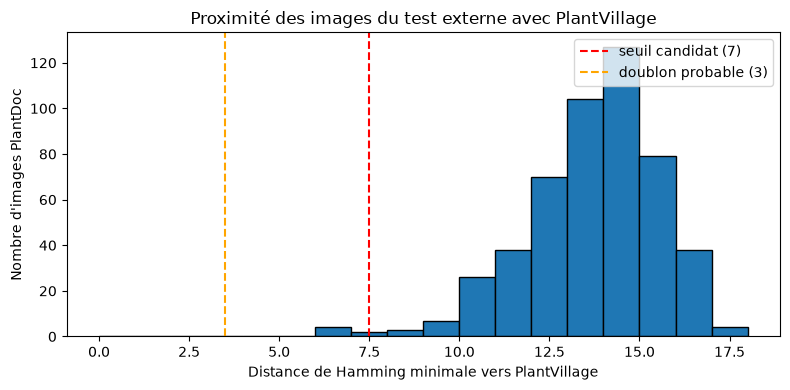

Figure 1 - Distribution de la distance minimale entre chaque image PlantDoc et PlantVillage ; les copies seraient proches de 0.


In [5]:
cum = pd.DataFrame({"distance_max": range(0, 11)})
cum["n_images_pd"] = [(best["distance"] <= t).sum() for t in cum["distance_max"]]
display(cum)
print("Tableau 3 - Nombre d'images PlantDoc ayant au moins une image PlantVillage à distance de Hamming inférieure ou égale au seuil.")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(best["distance"], bins=range(0, int(best["distance"].max()) + 2), edgecolor="black")
ax.axvline(THRESHOLD + 0.5, color="red", linestyle="--", label=f"seuil candidat ({THRESHOLD})")
ax.axvline(SURE + 0.5, color="orange", linestyle="--", label=f"doublon probable ({SURE})")
ax.set_xlabel("Distance de Hamming minimale vers PlantVillage")
ax.set_ylabel("Nombre d'images PlantDoc")
ax.set_title("Proximité des images du test externe avec PlantVillage")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "fig_distances.png", dpi=150)
plt.show()
print("Figure 1 - Distribution de la distance minimale entre chaque image PlantDoc et PlantVillage ; les copies seraient proches de 0.")

## 4. Contrôle visuel des candidats

Une vraie copie est la **même photo** (même feuille, mêmes taches), et en général de **la même classe**. Une paire de classes différentes, ou de feuilles visiblement différentes, est un faux positif.

6 candidat(s) à distance <= 7 ; dont 0 doublon(s) probable(s) (<= 3).


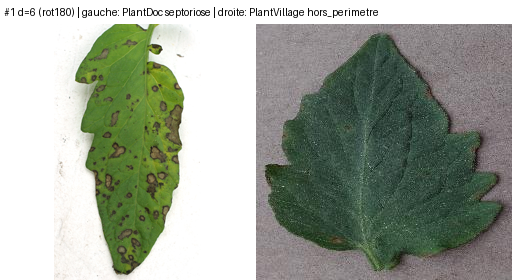

Figure - Paire #1 : même photo ? (distance 6, classes PlantDoc/PlantVillage : septoriose / hors_perimetre).


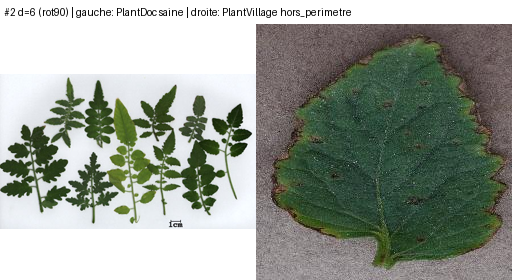

Figure - Paire #2 : même photo ? (distance 6, classes PlantDoc/PlantVillage : saine / hors_perimetre).


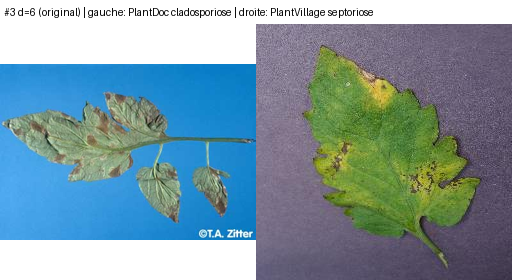

Figure - Paire #3 : même photo ? (distance 6, classes PlantDoc/PlantVillage : cladosporiose / septoriose).


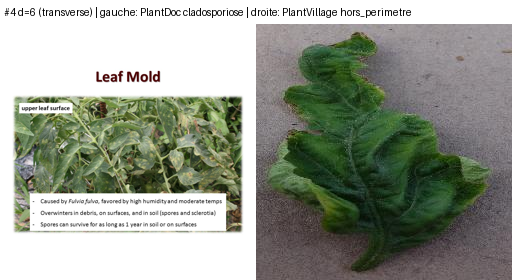

Figure - Paire #4 : même photo ? (distance 6, classes PlantDoc/PlantVillage : cladosporiose / hors_perimetre).


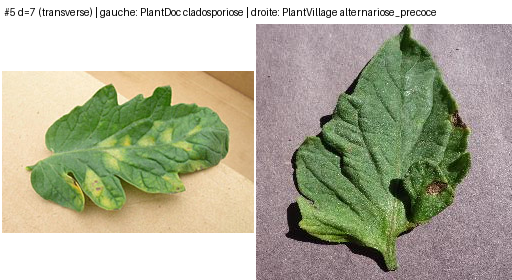

Figure - Paire #5 : même photo ? (distance 7, classes PlantDoc/PlantVillage : cladosporiose / alternariose_precoce).


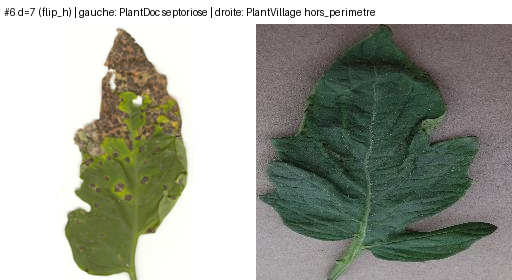

Figure - Paire #6 : même photo ? (distance 7, classes PlantDoc/PlantVillage : septoriose / hors_perimetre).


In [6]:
cand = best[best["distance"] <= THRESHOLD].copy()
cand["niveau"] = np.where(cand["distance"] <= SURE, "doublon_probable", "a_examiner")
print(f"{len(cand)} candidat(s) à distance <= {THRESHOLD} ; dont {int((cand['distance'] <= SURE).sum())} doublon(s) probable(s) (<= {SURE}).")


def pair_sheet(pd_path, pv_path, title, tile=256):
    sheet = Image.new("RGB", (2 * tile, tile + 24), "white")
    ImageDraw.Draw(sheet).text((4, 6), title, fill="black")
    for k, p in enumerate((pd_path, pv_path)):
        with Image.open(p) as im:
            im = im.convert("RGB")
            im.thumbnail((tile, tile))
            sheet.paste(im, (k * tile + (tile - im.width) // 2, 24 + (tile - im.height) // 2))
    return sheet


(OUT / "paires").mkdir(exist_ok=True)
for i, r in enumerate(cand.head(N_PAIRS).itertuples(), 1):
    title = f"#{i} d={r.distance} ({r.variante}) | gauche: PlantDoc {r.pd_class} | droite: PlantVillage {r.pv_class}"
    s = pair_sheet(PD_ROOT / r.pd_relpath, PV_ROOT / r.pv_relpath, title)
    s.save(OUT / "paires" / f"paire_{i:02d}.png")
    display(s)
    print(f"Figure - Paire #{i} : même photo ? (distance {r.distance}, classes PlantDoc/PlantVillage : {r.pd_class} / {r.pv_class}).")

## 5. Décisions

Le fichier `candidats_contamination.csv` contient la colonne `decision` (valeur initiale `A_EXAMINER`). Après contrôle visuel, remplacez-la par :
- `CONFIRME_CONTAMINATION` : c'est la même photo → l'image PlantDoc sera **exclue du test externe** ;
- `FAUX_POSITIF` : photos différentes.

Relancer le notebook **conserve** vos décisions déjà saisies.

In [7]:
dec_path = OUT / "candidats_contamination.csv"
cand_out = cand.copy()
cand_out["decision"] = "A_EXAMINER"
if dec_path.exists():
    old = pd.read_csv(dec_path)[["pd_image_id", "decision"]].rename(columns={"decision": "decision_prec"})
    cand_out = cand_out.merge(old, on="pd_image_id", how="left")
    cand_out["decision"] = cand_out["decision_prec"].fillna("A_EXAMINER")
    cand_out = cand_out.drop(columns="decision_prec")
cand_out.to_csv(dec_path, index=False)
best.to_csv(OUT / "meilleures_correspondances.csv", index=False)
print(f"Décisions enregistrées dans {dec_path}")
print(cand_out["decision"].value_counts().to_string())

Décisions enregistrées dans contamination\candidats_contamination.csv
decision
A_EXAMINER    6


## 6. Bilan et exclusions du test externe

In [8]:
dec = pd.read_csv(dec_path)
confirmed = dec[dec["decision"] == "CONFIRME_CONTAMINATION"]
pending = dec[dec["decision"] == "A_EXAMINER"]

confirmed[["pd_image_id", "pd_class", "pv_image_id", "distance"]].to_csv(OUT / "pd_exclusions_contamination.csv", index=False)

summary = {
    "copies_exactes_sha256": len(common),
    "images_pd_test_externe": int(len(pd_ext)),
    "candidats_distance_<=%d" % THRESHOLD: int(len(cand)),
    "doublons_probables_distance_<=%d" % SURE: int((best["distance"] <= SURE).sum()),
    "distance_minimale_observee": int(best["distance"].min()),
    "contaminations_confirmees": int(len(confirmed)),
    "candidats_restant_a_examiner": int(len(pending)),
}
(OUT / "bilan_contamination.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.Series(summary).rename("valeur").to_frame())
print("Tableau 4 - Bilan du contrôle de contamination.")

if len(confirmed):
    display(confirmed.groupby("pd_class").size().rename("n_exclues").reset_index())
    print("Tableau 5 - Images PlantDoc à exclure du test externe, par classe.")

if len(pending):
    print(f"Il reste {len(pending)} candidat(s) à examiner : mettez à jour la colonne decision, puis relancez.")
else:
    print("Tous les candidats ont été examinés.")

,valeur
copies_exactes_sha256,0
images_pd_test_externe,502
candidats_distance_<=7,6
doublons_probables_distance_<=3,0
distance_minimale_observee,6
contaminations_confirmees,0
candidats_restant_a_examiner,6


Tableau 4 - Bilan du contrôle de contamination.
Il reste 6 candidat(s) à examiner : mettez à jour la colonne decision, puis relancez.


## 7. À consigner dans le rapport

**Phrase de méthode :**
> « Nous avons vérifié l'absence de recouvrement entre le test externe (PlantDoc, cinq classes, [N] images) et PlantVillage : comparaison des empreintes SHA-256, puis des empreintes perceptuelles (dHash 64 bits, huit orientations) contre toutes les images de tomate de PlantVillage, avec contrôle visuel des candidats à une distance de Hamming inférieure ou égale à [seuil]. »

**Phrase de résultat (à adapter aux valeurs du Tableau 4) :**
> « Aucune copie exacte n'a été trouvée ; la distance minimale observée est de [d] ; [k] candidat(s) ont été examinés visuellement, [m] contamination(s) confirmée(s), exclue(s) du test externe. »

**Limites :** les recadrages importants, changements de couleur et incrustations ne sont pas détectés ; l'absence de candidat réduit le risque de contamination sans l'éliminer.